# AST — reference baseline

This is the `native_inputs_v2` experiment copy. In Google Colab, upload this notebook using **File → Upload notebook**. The accompanying `README-FINAL-EXPERIMENTS.md` explains the input front end, run configuration and result files.

# AST — reference baseline: pretrained sound-classification experiment

Run top to bottom in a fresh Colab runtime for each model. Use the same `RUN_TAG`, seed,
input annotations/audio, exclusion policy, and evaluation code in all five notebooks.
Required inputs are `annotations.csv` and `sonycWavs.zip`. AST is the designated reference
baseline; BAT, EAT, and SSLAM are transformer comparators, and VGGish is the CNN comparator.

The suite holds the audio selection, label construction, train/validation/test membership,
metric definitions, and checkpoint-selection criterion constant. Each pretrained model gets
its documented input frontend rather than an artificially identical feature tensor. Thus the
primary comparison is between pretrained model systems (including their native front ends),
not architecture alone. See `README-FINAL-EXPERIMENTS.md` for assumptions and run guidance.

The initial run profile allows up to 10 epochs, uses AdamW, selects the best checkpoint by
validation mAP, and logs one concise line per epoch. Learning rates and batch sizes are
starting settings, not claimed optima. This ZIP runs one seed by default; repeat with new seeds
and run tags before making strong claims about run-to-run variability.


## Runtime setup and dependencies

This cell prepares the Google Colab session. The first install line contains libraries shared by the data-ingestion, feature, metric, and plotting code. Any additional install line is specific to the model implementation in this notebook. Mounting Google Drive makes the annotation CSV and WAV archive available at the paths configured below.

Run the notebook in a fresh runtime when practical, and run cells in order. Package installation, model downloads, and Drive access are setup steps; they do not train the classifier by themselves.

In [2]:
# Install dependencies for this notebook; model-specific libraries differ by experiment.
%pip install -q soundfile==0.13.1 scipy pandas scikit-learn matplotlib seaborn tqdm
%pip install -q timm==0.4.5 wget
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Shared protocol helpers

The next cell defines the common functions used throughout the five experiments. It sets a canonical order for the eight coarse sound labels, validates how annotation rows become multi-label targets, converts audio to a canonical waveform representation, builds a manifest that links filenames to labels and checksums, and computes the evaluation metrics. Most of these definitions do no work until they are called by later cells.

Keeping this code identical is intended to make differences in data handling and scoring less likely to explain differences between model results. The label order is especially important: each model's eight output values, every target vector, and the saved per-class results must refer to the same label in the same column.

In [3]:
# Standard-library utilities plus shared scientific, audio, and metric dependencies.
import os, sys, json, hashlib, random, math, shutil, zipfile, platform, time
from pathlib import Path
import importlib.metadata
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
from sklearn.metrics import average_precision_score, f1_score, accuracy_score

# Raw annotation-column names mapped to the canonical target names used downstream.
LABEL_MAP = {
    '1_engine_presence': 'engine_presence',
    '2_machinery-impact_presence': 'machinery-impact_presence',
    '3_non-machinery-impact_presence': 'non-machinery-impact_presence',
    '4_powered-saw_presence': 'powered-saw_presence',
    '5_alert-signal_presence': 'alert-signal_presence',
    '6_music_presence': 'music_presence',
    '7_human-voice_presence': 'human-voice_presence',
    '8_dog_presence': 'dog_presence',
}
# Keep this class order fixed across targets, model outputs, metrics, and saved files.
labels = list(LABEL_MAP.values())

# Stable hashes let the notebooks detect protocol/settings changes between runs.
def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False))
    temp.replace(path)

# Convert annotation rows to one eight-label target vector per audio filename.
def build_targets(annotations):
    # Reject incomplete schemas early instead of silently training on partial columns.
    required = ['split', 'audio_filename', 'annotator_id', *LABEL_MAP]
    missing = set(required) - set(annotations.columns)
    if missing:
        raise ValueError(f'Missing annotation columns: {sorted(missing)}')
    df = annotations[required].rename(columns=LABEL_MAP).copy()
    if df[['split', 'audio_filename', 'annotator_id']].isna().any().any():
        raise ValueError('Missing split, filename, or annotator ID')
    df['annotator_id'] = pd.to_numeric(df['annotator_id'], errors='raise')
    if not df['split'].isin(['train', 'validate', 'test']).all():
        raise ValueError('Unexpected split values')
    if (df.groupby('audio_filename')['split'].nunique() > 1).any():
        raise ValueError('A filename belongs to multiple splits')
    # Training uses individual annotators (IDs > 0); validation/test use the ID-0
    # reference rows. This split/annotator convention is part of the experiment protocol.
    selected = {
        'train': df[(df['split'] == 'train') & (df.annotator_id > 0)],
        'validate': df[(df['split'] == 'validate') & (df.annotator_id == 0)],
        'test': df[(df['split'] == 'test') & (df.annotator_id == 0)],
    }
    targets = {}
    for split, rows in selected.items():
        rows = rows.copy()
        if rows.empty:
            raise ValueError(f'{split}: no eligible annotations')
        rows[labels] = rows[labels].apply(pd.to_numeric, errors='raise')
        if not rows[labels].isin([0, 1]).all().all():
            raise ValueError(f'{split}: coarse labels must be 0/1; unknowns are not silently recoded')
        if rows.duplicated(['audio_filename', 'annotator_id']).any():
            raise ValueError(f'{split}: duplicate filename/annotator records; resolve upstream')
        if split == 'train':
            # Element-wise max implements an any-positive vote: a class is present if
            # at least one selected training annotator marked it 1.
            y = rows.groupby('audio_filename', sort=True)[labels].max()
        else:
            # The reference-label splits must already have one target row per clip.
            if rows.audio_filename.duplicated().any():
                raise ValueError(f'{split}: duplicate verified labels')
            y = rows.set_index('audio_filename')[labels].sort_index()
        targets[split] = y.astype('int64')
    for a, b in [('train', 'validate'), ('train', 'test'), ('validate', 'test')]:
        if not targets[a].index.intersection(targets[b].index).empty:
            raise ValueError(f'Split overlap: {a}/{b}')
    return targets

# Canonicalize every source clip once for all models: mono, 16 kHz, 10 seconds.
def load_waveform(path):
    waveform, sr = sf.read(path, dtype='float32', always_2d=True)
    if len(waveform) == 0 or sr <= 0 or not np.isfinite(waveform).all():
        raise ValueError('Empty/nonfinite audio or invalid sample rate')
    # Average channels to mono so channel layout does not change model inputs.
    waveform = waveform.mean(axis=1, dtype=np.float32)
    # Use polyphase resampling rather than merely relabeling the sample rate.
    if sr != 16000:
        factor = math.gcd(sr, 16000)
        waveform = resample_poly(waveform, 16000 // factor, sr // factor).astype(np.float32)
    # Keep up to 10 seconds but do not pad here: model-native front ends must
    # see the true clip duration before their own spectrogram/frame padding.
    waveform = waveform[:160000]
    if not np.isfinite(waveform).all():
        raise ValueError('Nonfinite audio after resampling')
    return np.ascontiguousarray(waveform, dtype=np.float32)

# Extract only WAV members and reject duplicate basenames that would overwrite a clip.
def extract_audio(archive, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        members = {}
        for info in z.infolist():
            if info.is_dir() or info.filename.startswith('__MACOSX/') or not info.filename.lower().endswith('.wav'):
                continue
            name = Path(info.filename).name
            if name in members:
                raise ValueError(f'Duplicate WAV basename in archive: {name}')
            members[name] = info
        if not members:
            raise ValueError('No WAV files found in archive')
        for name, info in members.items():
            path = destination / name
            # Re-extract from the archive; do not trust files from a previous session.
            with z.open(info) as src, open(path, 'wb') as dst:
                shutil.copyfileobj(src, dst)
    return {name: destination / name for name in members}

# Validate referenced audio and join each target row to hashes of its source/canonical wave.
def prepare_manifest(targets, audio_paths, exclude_invalid=False):
    manifests, excluded = {}, []
    for split, y in targets.items():
        records = []
        for name, row in y.iterrows():
            if Path(name).name != name:
                raise ValueError(f'Expected a basename in annotations: {name}')
            try:
                if name not in audio_paths:
                    raise FileNotFoundError('Not present in supplied audio archive')
                path = audio_paths[name]
                waveform = load_waveform(path)
                checksum = file_sha256(path)
                wave_checksum = hashlib.sha256(waveform.tobytes()).hexdigest()
            # Record bad/missing files for a clear failure report or explicit exclusion.
            except (OSError, ValueError, RuntimeError) as exc:
                excluded.append({'split': split, 'audio_filename': name, 'reason': str(exc)})
                continue
            records.append({'audio_filename': name, 'split': split,
                            'audio_sha256': checksum, 'waveform_sha256': wave_checksum,
                            **{label: int(row[label]) for label in labels}})
        manifests[split] = pd.DataFrame(records, columns=['audio_filename', 'split', 'audio_sha256', 'waveform_sha256', *labels])
    # By default the caller fails if any clip is invalid; exclusion must be explicit.
    if excluded and not exclude_invalid:
        return manifests, excluded
    if any(m.empty for m in manifests.values()):
        raise ValueError('At least one split is empty after audio validation')
    combined = pd.concat(manifests.values(), ignore_index=True)
    # Identical canonical waveforms across splits may indicate leakage; stop for review.
    if (combined.groupby('waveform_sha256')['split'].nunique() > 1).any():
        raise ValueError('Identical canonical audio occurs in different splits; investigate leakage')
    return manifests, excluded

# One scoring implementation shared by validation selection and held-out test evaluation.
def evaluate_multilabel(y_true, probabilities, threshold=0.5):
    y = np.asarray(y_true)
    p = np.asarray(probabilities)
    if y.shape != p.shape or y.ndim != 2 or y.shape[1] != len(labels) or not len(y):
        raise ValueError('Evaluation arrays must have shape (clips, eight labels)')
    if not np.isin(y, [0, 1]).all() or not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError('Invalid evaluation labels or probabilities')
    # The convention is strictly greater than the threshold (not greater-than-or-equal).
    pred = (p > threshold).astype(np.int64)
    # Explicit convention: classes with zero positive support contribute AP=0 to macro AP.
    ap = np.array([average_precision_score(y[:, i], p[:, i]) if y[:, i].sum() else 0.0
                   for i in range(len(labels))])
    micro_ap = average_precision_score(y.ravel(), p.ravel()) if y.sum() else 0.0
    # mAP and macro_AUPRC_AP intentionally report the same unweighted mean class AP.
    metrics = {
        'subset_accuracy': float(accuracy_score(y, pred)),
        'f1_micro': float(f1_score(y, pred, average='micro', zero_division=0)),
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)),
        'mAP': float(ap.mean()),
        'macro_AUPRC_AP': float(ap.mean()),
        'micro_AUPRC_AP': float(micro_ap),
    }
    per_class = pd.DataFrame({'label': labels, 'AP': ap, 'positive_support': y.sum(axis=0).astype(int)})
    return metrics, per_class, pred


## Experiment configuration and output isolation

This cell holds the experiment-wide settings. `MODEL_NAME` identifies the model-specific branch, while the paths identify the source annotations/audio and where results are written. Keep the data paths, `RUN_TAG`, `SEED`, threshold, and invalid-audio policy aligned across notebooks when making a comparison.

The shared data contract records the common audio/label protocol; model-native front-end details are saved separately in run_info.json; a protocol hash is checked across notebooks using the same run tag. Model outputs live in `normalized_results/AST/native_inputs_v2/` (model-specific folder, then run tag). Checkpoints, tables, resource reports, and plot PNGs are all written there. `RESUME=True` is for continuing an existing neural-model run and requires both compatible checkpoint files; for a genuinely new run, use a fresh run tag or deliberately start with `RESUME=False`. Existing results are protected from accidental overwrite.

In [4]:
# Model-specific runtime profile. Values are conservative starting points, not claimed optima.
MODEL_NAME = 'ast'
MODEL_ROLE = 'reference baseline'
# Shared suite marker changes when training behavior/logging changes; shared data protocol remains fixed.
SUITE_CODE_HASH = 'f9000319fdb326ae5e34ac37872596e1e8be8d81ff0a9d7204335de2b13acabf'  # shared native-frontend suite version fingerprint
# Inputs and result artifacts live under the same Drive project folder.
DATA_ROOT = Path('/content/drive/MyDrive/A/thesis')
ANNOTATIONS_PATH = DATA_ROOT / 'annotations.csv'
AUDIO_ARCHIVE = DATA_ROOT / 'sonycWavs.zip'
AUDIO_DIR = Path('/content/thesis_normalized_audio')
OUTPUT_ROOT = DATA_ROOT / 'normalized_results'
# New directory avoids accidental resume/overwrite of checkpoints created by the prior optimizer/settings.
RUN_TAG = 'native_inputs_v2'
# Shared task/evaluation protocol; these are not model-selection hyperparameters.
SEED = 42
THRESHOLD = 0.5
EXCLUDE_INVALID_AUDIO = False
# GPU micro-batches differ by model footprint. CPU fallback is set to 1 after device detection.
# AST uses a longer attention sequence; BAT/EAT/SSLAM use shorter patch grids; VGGish can batch patches.
GPU_BATCH_SIZE_BY_MODEL = {'ast': 1, 'bat': 2, 'eat': 2, 'sslam': 2, 'vgg': 4}
BATCH_SIZE = 1  # selected for the detected device in the shared runtime cell
LEARNING_RATE = 1e-5
TASK_HEAD_LEARNING_RATE = 1e-4  # newly initialized task heads adapt faster than pretrained backbones
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
NUM_EPOCHS = 10  # same initial epoch budget across the five model systems; select best by validation mAP
NUM_WORKERS = 0  # selected after device detection; GPU runs use two data workers
USE_AMP = True
RESUME = False
# Stable, notebook-specific output path; all metrics, checkpoints, and plots go here.
AST_OUTPUT_DIR = OUTPUT_ROOT / 'AST' / RUN_TAG
AST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Model-specific outputs, including PNG plots, will be saved under:', AST_OUTPUT_DIR)


Model-specific outputs, including PNG plots, will be saved under: /content/drive/MyDrive/A/thesis/normalized_results/AST/native_inputs_v2


## Shared ETL and audio validation

This is the point where the configured inputs are actually read and checked. The annotation table is reduced to the eight target columns and converted into one target vector per filename. The current protocol uses training annotations with `annotator_id > 0` and combines them with an element-wise maximum: a class is positive if any selected training annotator marked it present. Validation and test targets use the `annotator_id == 0` rows and require exactly one such target row per clip. Label values must already be binary (`0`/`1`); unknown values are rejected rather than silently converted.

The WAV archive is extracted by basename, then each target clip is checked for existence and readable, finite audio. Every accepted waveform is converted to mono, resampled to 16 kHz, truncated to the first 10 seconds but not waveform-padded; each model frontend applies its own feature-frame padding policy. The manifest stores source-file and canonical-waveform hashes alongside the labels. The hashes help detect changed audio and identical canonical waveforms appearing in different splits; they do not by themselves prove that all possible forms of dataset leakage are absent.

By default, any missing or corrupt referenced audio stops the run. `EXCLUDE_INVALID_AUDIO=True` explicitly allows those clips to be excluded, but use the same policy in all five notebooks. The cell writes per-split manifests and a data-contract JSON so each result can be traced to the same declared protocol.

In [5]:
# Read source annotations and apply shared label/annotator aggregation rules.
ETL_STARTED = time.perf_counter()
annotations = pd.read_csv(ANNOTATIONS_PATH)
targets = build_targets(annotations)
# Extract WAVs and build a filename -> local path lookup for the manifest.
audio_paths = extract_audio(AUDIO_ARCHIVE, AUDIO_DIR)
# Preflight every target clip; hashes will be checked again during Dataset reads.
manifests, excluded = prepare_manifest(targets, audio_paths, EXCLUDE_INVALID_AUDIO)
pd.DataFrame(excluded, columns=['split', 'audio_filename', 'reason']).to_csv(AST_OUTPUT_DIR / 'excluded_audio.csv', index=False)
if excluded and not EXCLUDE_INVALID_AUDIO:
    raise RuntimeError('Missing/corrupt audio: see excluded_audio.csv. Repair the source archive, or explicitly enable the same exclusion policy in ALL notebooks.')
# Index targets by filename so loader order can be compared directly with expected labels.
y_train, y_val, y_test = [m.set_index('audio_filename')[labels].astype('int64') for m in manifests.values()]
for split, manifest in manifests.items():
    manifest.to_csv(AST_OUTPUT_DIR / f'{split}_manifest.csv', index=False)
# Save the decisions that define the shared data protocol, not just a model score.
protocol = {
    'version': 'thesis-native-inputs-v2', 'seed': SEED,
    'annotations_sha256': file_sha256(ANNOTATIONS_PATH),
    'labels': labels, 'train_labels': 'train split, annotator_id > 0, any-positive vote',
    'evaluation_labels': 'validate/test split, annotator_id == 0',
    'waveform': 'soundfile float32; average channels; scipy resample_poly to 16kHz; retain at most first 160000 samples without waveform padding; model frontend handles its own frame padding',
    'excluded_audio': excluded, 'exclude_invalid_audio': EXCLUDE_INVALID_AUDIO,
    'manifest': pd.concat(manifests.values()).to_dict(orient='records'),
    'model_features': 'native model-specific frontend; see model-specific FEATURE_FRONTEND_DETAILS in run_info.json',
    'threshold': THRESHOLD, 'threshold_comparison': '>',
    'AP': 'sklearn non-interpolated AP; unweighted class mean = mAP; zero-support class AP=0',
    'audio_versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'soundfile', 'torch', 'torchaudio', 'scikit-learn']},
}
# This hash should match across notebooks with the same inputs and shared protocol.
# The shared contract below is read-only after first creation; a per-model copy is also saved in this notebook's output folder.
DATA_PROTOCOL_HASH = digest_json(protocol)
contract_path = OUTPUT_ROOT / f'{RUN_TAG}_data_contract.json'
contract = {'data_protocol_hash': DATA_PROTOCOL_HASH, 'protocol': protocol}
# Refuse a silent protocol mismatch when another model already used this RUN_TAG.
if contract_path.exists():
    if json.loads(contract_path.read_text())['data_protocol_hash'] != DATA_PROTOCOL_HASH:
        raise RuntimeError('Shared data/protocol differs from another run with this RUN_TAG. Resolve the discrepancy or use a new RUN_TAG in ALL notebooks.')
else:
    write_json(contract_path, contract)
write_json(AST_OUTPUT_DIR / 'data_contract.json', contract)
# Quick audit summary: split sizes and per-label positive counts before training.
print('Data protocol hash:', DATA_PROTOCOL_HASH)
print('Clip counts:', {s: len(m) for s, m in manifests.items()})
print('Excluded clips:', len(excluded))
ETL_SECONDS = time.perf_counter() - ETL_STARTED
print(f'ETL/preflight: {ETL_SECONDS/60:.1f} min')
display(pd.DataFrame({s: m[labels].sum() for s, m in manifests.items()}))


Data protocol hash: a5ea75a1897335283e38a85e382a8daafdf03e46197ed8dd2b11ef37dd5d6fed
Clip counts: {'train': 13538, 'validate': 538, 'test': 664}
Excluded clips: 0
ETL/preflight: 15.6 min


,train,validate,test
engine_presence,7289,266,380
machinery-impact_presence,2705,22,26
non-machinery-impact_presence,1466,77,258
powered-saw_presence,1479,28,9
alert-signal_presence,3407,108,130
music_presence,1072,37,59
human-voice_presence,4828,241,307
dog_presence,984,6,29


## Shared waveform identity; native model-specific features

The manifest provides a canonical mono waveform at 16 kHz, truncated to at most 10 seconds. It is **not padded at the waveform stage**: that detail matters because each pretrained model applies its own feature extraction and padding sequence. The Dataset re-reads the waveform, verifies its canonical hash, and then uses the frontend for the selected model.

- **AST:** Kaldi filterbanks, 128 bins and a 10 ms frame shift; frames are padded/cropped to 1024 and normalized with the AST AudioSet mean/std.
- **BAT:** its released power-Mel → dB (`top_db=80`) → per-example min-max pipeline, followed by padding/cropping to 1024 frames.
- **EAT and SSLAM:** Kaldi filterbanks and the EAT/SSLAM checkpoint normalization constants, with a 1024-frame target.
- **VGGish:** the reference `torchvggish` waveform frontend creates native 96×64 log-Mel patches. Patch embeddings are averaged into one clip representation by the model adapter.

These frontends are intentionally not numerically identical. They follow the documented input conventions for each pretrained checkpoint, so the main comparison is between pretrained systems (architecture, pretraining and native frontend together). The common Dataset returns `(features, target_vector, filename)`; filename alignment is asserted during validation and test evaluation. VGGish clips can yield different patch counts, so its collator keeps features as a list while the transformer input tensors are stacked.

In [6]:
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader

# Seed each random generator used by model initialization and shuffled training order.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Favor repeatability over cuDNN autotuning. Some kernels can still vary by hardware/software.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Conservative model-specific micro-batches; lower a model's value if a GPU OOMs.
if device.type == 'cuda':
    BATCH_SIZE = int(GPU_BATCH_SIZE_BY_MODEL.get(MODEL_NAME, 1))
    NUM_WORKERS = 2
else:
    BATCH_SIZE = 1
    NUM_WORKERS = 0

# Native input front ends, constructed once per run. The waveform itself is kept at its
# true post-resampling length (up to 10 s); each front end performs its own frame padding.
AST_NORM_MEAN, AST_NORM_STD = -4.2677393, 4.5689974
EAT_NORM_MEAN, EAT_NORM_STD = -4.268, 4.569
TARGET_FRAMES = 1024
NUM_MEL_BINS = 128

# BAT's pinned repository includes the reference BatAudioProcessor. It is loaded in
# the BAT model-initialization cell so the model's own config controls its frontend.


def fit_frame_length(features, target_frames=TARGET_FRAMES, pad_value=0.0):
    """Crop/pad a (time, mel) feature matrix along time without changing mel bins."""
    features = features[:target_frames]
    if features.shape[0] < target_frames:
        features = torch.nn.functional.pad(
            features, (0, 0, 0, target_frames - features.shape[0]), value=pad_value)
    return features


def kaldi_fbank_native(waveform, norm_mean, norm_std, center_waveform=True):
    """Checkpoint-style Kaldi fbank frontend; centering follows each model's published recipe."""
    audio = torch.from_numpy(np.asarray(waveform, dtype=np.float32).copy()).float()
    # EAT/SSLAM mean-center the waveform; the original AST frontend does not.
    if center_waveform:
        audio = audio - audio.mean()
    # Kaldi's default analysis window is 25 ms. Guard unusually short but valid recordings.
    if audio.numel() < 400:
        audio = torch.nn.functional.pad(audio, (0, 400 - audio.numel()))
    features = torchaudio.compliance.kaldi.fbank(
        audio.unsqueeze(0), htk_compat=True, sample_frequency=16000,
        use_energy=False, window_type='hanning', num_mel_bins=NUM_MEL_BINS,
        dither=0.0, frame_shift=10)
    # The frontend pads/crops filterbank frames to 1024 before checkpoint normalization.
    features = fit_frame_length(features, TARGET_FRAMES, pad_value=0.0)
    return ((features - norm_mean) / (norm_std * 2.0)).float()


def bat_native_features(waveform):
    """Run BAT's pinned reference processor; output is one [channel, time, mel] tensor."""
    audio = torch.from_numpy(np.asarray(waveform, dtype=np.float32).copy())
    # The bundled processor uses centered STFT windows; ensure its reflection padding is valid.
    if audio.numel() < 1024:
        audio = torch.nn.functional.pad(audio, (0, 1024 - audio.numel()))
    if 'bat_processor' not in globals():
        raise RuntimeError('BAT native processor was not initialized; run the BAT model setup cell first.')
    features = bat_processor(audio)  # [batch=1, channel=1, time=1024, mel=128]
    if features.ndim != 4 or tuple(features.shape) != (1, 1, TARGET_FRAMES, NUM_MEL_BINS):
        raise RuntimeError(f'BAT processor returned unexpected shape {tuple(features.shape)}')
    return features.squeeze(0).float()  # [1, 1024, 128], ready for DataLoader stacking


def model_features(waveform):
    """Convert one canonical mono waveform using the selected checkpoint's native frontend."""
    if MODEL_NAME == 'ast':
        features = kaldi_fbank_native(waveform, AST_NORM_MEAN, AST_NORM_STD, center_waveform=False)  # (1024, 128)
    elif MODEL_NAME in ('eat', 'sslam'):
        features = kaldi_fbank_native(waveform, EAT_NORM_MEAN, EAT_NORM_STD).unsqueeze(0)  # (1, 1024, 128)
    elif MODEL_NAME == 'bat':
        features = bat_native_features(waveform).unsqueeze(0)  # (1, 1024, 128)
    elif MODEL_NAME == 'vgg':
        # VGGish's reference frontend consumes 16-kHz waveforms and creates 96x64 examples.
        vgg_waveform = np.asarray(waveform, dtype=np.float32)
        # A clip shorter than one VGGish example has no complete patch; pad only this edge case.
        if len(vgg_waveform) < 16000:
            vgg_waveform = np.pad(vgg_waveform, (0, 16000 - len(vgg_waveform)))
        patches = vggish_input.waveform_to_examples(vgg_waveform, 16000, return_tensor=False)
        features = torch.as_tensor(np.asarray(patches), dtype=torch.float32).unsqueeze(1)
        if not len(features):
            raise ValueError('VGGish produced no 96x64 patches')
    else:
        raise ValueError(f'Unknown model frontend: {MODEL_NAME}')
    if not torch.isfinite(features).all():
        raise ValueError(f'Nonfinite native input features for {MODEL_NAME}')
    return features

# Re-read each waveform at access time and verify it matches the preflight canonical hash.
class SONYCDataset(Dataset):
    def __init__(self, manifest):
        self.manifest = manifest.reset_index(drop=True)
    def __len__(self):
        return len(self.manifest)
    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        filename = row['audio_filename']
        waveform = load_waveform(audio_paths[filename])
        if hashlib.sha256(waveform.tobytes()).hexdigest() != row['waveform_sha256']:
            raise RuntimeError(f'Audio changed since preflight: {filename}')
        features = model_features(waveform)
        target = torch.tensor(row[labels].to_numpy(dtype=np.float32))
        return features, target, filename

# VGGish can yield a different number of patches per clip; keep those feature tensors as a list.
def collate_examples(batch):
    features, targets_batch, filenames = zip(*batch)
    features = list(features) if MODEL_NAME == 'vgg' else torch.stack(features)
    return features, torch.stack(targets_batch), list(filenames)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

train_generator = torch.Generator().manual_seed(SEED)

# Only training shuffles. Persistent workers avoid restarting data workers each epoch.
def make_loader(manifest, shuffle):
    return DataLoader(SONYCDataset(manifest), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, collate_fn=collate_examples,
                      pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0,
                      worker_init_fn=seed_worker,
                      generator=train_generator if shuffle else torch.Generator().manual_seed(SEED))

def to_device(features):
    if isinstance(features, list):
        return [item.to(device, non_blocking=(device.type == 'cuda')) for item in features]
    return features.to(device, non_blocking=(device.type == 'cuda'))

# Discard only stdout emitted inside individual model calls; warnings/errors on stderr stay visible.
import contextlib
class _DiscardStdout:
    def write(self, value): return len(value)
    def flush(self): pass
_DISCARD_STDOUT = _DiscardStdout()
def quiet_model_forward(features):
    with contextlib.redirect_stdout(_DISCARD_STDOUT):
        return model(features)

# Resource helpers are optional-dependency tolerant and work on Colab CPU/GPU runtimes.
def synchronize_device():
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def reset_gpu_peak_memory():
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)

def gpu_memory_snapshot():
    if device.type != 'cuda':
        return {'gpu_peak_allocated_mb': None, 'gpu_peak_reserved_mb': None,
                'gpu_current_allocated_mb': None}
    mib = 1024 ** 2
    return {
        'gpu_peak_allocated_mb': round(torch.cuda.max_memory_allocated(device) / mib, 2),
        'gpu_peak_reserved_mb': round(torch.cuda.max_memory_reserved(device) / mib, 2),
        'gpu_current_allocated_mb': round(torch.cuda.memory_allocated(device) / mib, 2),
    }

def process_resource_snapshot():
    snapshot = {}
    try:
        import psutil
        process = psutil.Process()
        snapshot['process_rss_mb'] = round(process.memory_info().rss / (1024 ** 2), 2)
        vm = psutil.virtual_memory()
        snapshot['system_ram_total_mb'] = round(vm.total / (1024 ** 2), 2)
        snapshot['system_ram_available_mb'] = round(vm.available / (1024 ** 2), 2)
    except Exception:
        snapshot.update(process_rss_mb=None, system_ram_total_mb=None, system_ram_available_mb=None)
    try:
        import resource
        peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        # Linux reports KiB; macOS reports bytes.
        snapshot['process_peak_rss_mb'] = round(max(peak / (1024 ** 2 if platform.system() == 'Darwin' else 1024), snapshot.get('process_rss_mb') or 0.0), 2)
    except Exception:
        snapshot['process_peak_rss_mb'] = None
    return snapshot

def parameter_counts(model_obj):
    return {
        'total_parameters': int(sum(p.numel() for p in model_obj.parameters())),
        'trainable_parameters': int(sum(p.numel() for p in model_obj.parameters() if p.requires_grad)),
    }


In [7]:
from google.colab import files
from pathlib import Path
import shutil
import torch

filename = "audioset_10_10_0.4593.pth"
destination = Path("/content/thesis_model_sources/pretrained_models") / filename
destination.parent.mkdir(parents=True, exist_ok=True)

def is_expected_ast_checkpoint(path):
    path = Path(path)
    if not path.exists() or path.stat().st_size < 1024:
        return False
    try:
        with path.open("rb") as f:
            if f.read(256).lstrip().startswith(b"<"):
                return False  # HTML error/download page, not model weights
        state = torch.load(path, map_location="cpu", weights_only=True)
        return isinstance(state, dict) and "module.v.pos_embed" in state
    except Exception:
        return False

if is_expected_ast_checkpoint(destination):
    print("Reusing validated AST AudioSet checkpoint:", destination)
else:
    print(f"Upload {filename}. Use the official AST AudioSet checkpoint; HTML downloads are rejected.")
    uploaded = files.upload()
    if filename not in uploaded:
        raise ValueError(f"Please upload {filename}")
    candidate = Path(filename)
    if not is_expected_ast_checkpoint(candidate):
        raise ValueError("Uploaded file is not a valid AST AudioSet state dictionary.")
    shutil.copyfile(candidate, destination)
    print("Validated checkpoint installed:", destination)


Upload audioset_10_10_0.4593.pth. Use the official AST AudioSet checkpoint; HTML downloads are rejected.


Saving audioset_10_10_0.4593.pth to audioset_10_10_0.4593.pth
Validated checkpoint installed: /content/thesis_model_sources/pretrained_models/audioset_10_10_0.4593.pth


## Model initialization — AST reference baseline

AST uses the published AudioSet-pretrained AST base384 checkpoint. Its native input is a 128-bin Kaldi filterbank spectrogram, padded/cropped to 1024 time frames and normalized using AudioSet statistics to approximately zero mean and 0.5 standard deviation. The model's input-time dimension is therefore set to 1024, matching the checkpoint's 10-second recipe. Pretrained weights are validated before use; the task-specific output head is initialized for the eight coarse SONYC classes.

In [8]:
MODEL_INIT_STARTED = time.perf_counter()
import urllib.request, importlib.util
from contextlib import contextmanager

AST_REVISION = '31088be8a3f6ef96416145c4b8d43c81f99eba7a'
source_dir = Path('/content/thesis_model_sources/ast')
source_dir.mkdir(parents=True, exist_ok=True)
source_path = source_dir / 'ast_models.py'
source_url = f'https://raw.githubusercontent.com/YuanGongND/ast/{AST_REVISION}/src/models/ast_models.py'
source = urllib.request.urlopen(source_url, timeout=60).read().decode()
# Keep the official loader's strict=False behavior for checkpoint keys, and remove
# its internal autocast decorator so the shared training loop controls AMP consistently.
source = source.replace('    @autocast()\n', '')
source_path.write_text(source)

@contextmanager
def ast_environment():
    previous_cwd = Path.cwd()
    previous_home = os.environ.get('TORCH_HOME')
    work = source_dir / 'run'
    work.mkdir(exist_ok=True)
    try:
        os.chdir(work)
        yield
    finally:
        os.chdir(previous_cwd)
        if previous_home is None:
            os.environ.pop('TORCH_HOME', None)
        else:
            os.environ['TORCH_HOME'] = previous_home

with ast_environment():
    weight_path = Path('../../pretrained_models/audioset_10_10_0.4593.pth').resolve()
    weight_path.parent.mkdir(parents=True, exist_ok=True)
    if not weight_path.exists():
        temporary = weight_path.with_suffix('.download')
        urllib.request.urlretrieve('https://www.dropbox.com/s/cv4knew8mvbrnvq/audioset_0.4593.pth?dl=1', temporary)
        temporary.replace(weight_path)
    # Fail on invalid/unavailable AudioSet weights; never silently use ImageNet-only weights.
    pretrained_state = torch.load(weight_path, map_location='cpu', weights_only=True)
    if not isinstance(pretrained_state, dict) or 'module.v.pos_embed' not in pretrained_state:
        raise ValueError('Not the expected AST AudioSet state dictionary')
    del pretrained_state
    spec = importlib.util.spec_from_file_location('thesis_ast_models', source_path)
    ast_models = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(ast_models)
    model = ast_models.ASTModel(label_dim=len(labels), fstride=10, tstride=10,
                               input_fdim=128, input_tdim=1024,
                               imagenet_pretrain=True, audioset_pretrain=True, model_size='base384')
MODEL_IDENTITY = {'role': MODEL_ROLE, 'repository': 'YuanGongND/ast', 'revision': AST_REVISION,
                  'checkpoint': 'audioset_10_10_0.4593.pth', 'weights_sha256': file_sha256(weight_path),
                  'compatibility_edits': 'official checkpoint-loading semantics retained; shared AMP control'}
FEATURE_FRONTEND_DETAILS = {
    'frontend': 'torchaudio.compliance.kaldi.fbank (AST reference recipe)',
    'sample_rate_hz': 16000, 'num_mel_bins': 128, 'target_frames': 1024,
    'window_type': 'hanning', 'frame_shift_ms': 10, 'dither': 0.0,
    'waveform_mean_centered_before_fbank': False,
    'normalization_mean': -4.2677393, 'normalization_std': 4.5689974,
    'normalization_formula': '(fbank - mean) / (2 * std)',
}
FEATURE_ADAPTER = 'AST native Kaldi fbank: 1024x128 with AudioSet mean/std normalization'
MODEL_INIT_SECONDS = time.perf_counter() - MODEL_INIT_STARTED


---------------AST Model Summary---------------
ImageNet pretraining: True, AudioSet pretraining: True
frequncey stride=10, time stride=10
number of patches=1212


## Native frontend/model smoke test

Run one zero-audio example through the selected native frontend and model before starting the full experiment. This is a shape/API check, not a meaningful prediction or training step. It fails early if frontend output and model input expectations disagree.

In [9]:
# Frontend/model contract test: catches input shape or output-head mismatches before training.
_probe_waveform = np.zeros(16000, dtype=np.float32)
_probe_features = model_features(_probe_waveform)
model = model.to(device)
model.eval()
with torch.inference_mode():
    if MODEL_NAME == 'vgg':
        _probe_logits = model([_probe_features.to(device)])
    else:
        _probe_logits = model(_probe_features.unsqueeze(0).to(device))
if not isinstance(_probe_logits, torch.Tensor) or tuple(_probe_logits.shape) != (1, len(labels)):
    raise RuntimeError(f'{MODEL_NAME} output contract failed: expected (1, {len(labels)}), got {getattr(_probe_logits, "shape", type(_probe_logits))}')
if not torch.isfinite(_probe_logits).all():
    raise RuntimeError(f'{MODEL_NAME} produced nonfinite logits in the input smoke test')
model.train()
del _probe_waveform, _probe_features, _probe_logits
print(f'Native input smoke test passed: model={MODEL_NAME}, frontend={FEATURE_ADAPTER}, output=(1, {len(labels)})')

Native input smoke test passed: model=ast, frontend=AST native Kaldi fbank: 1024x128 with AudioSet mean/std normalization, output=(1, 8)


## AST training profile and optimization notes

AST creates a comparatively long attention-token sequence from the native 1024 × 128 input, so the CUDA profile deliberately starts with micro-batch 1. The task-specific head uses a higher initial learning rate (1e-4) than the pretrained encoder (1e-5). The training loop uses CUDA mixed precision when supported, AdamW with decoupled weight decay, and gradient clipping after AMP gradient unscaling. Per-epoch output now reports loss, validation mAP, timing, throughput, and peak allocated/reserved GPU memory.

The ten-epoch maximum and 1e-5 base learning rate are starting settings, not a hyperparameter search. Tune learning rate and epochs using **validation only**; keep the held-out test split untouched until final evaluation. If GPU memory allows, test a larger AST batch as a separately tagged run and report the changed setting.

## Train and select using validation mAP

The loader setup keeps training, validation, and test manifests separate. Only training batches update model parameters. The neural-model loop uses binary cross-entropy with logits for the eight independent labels and AdamW for optimization. Automatic mixed precision is enabled only when requested and a CUDA device is available. Validation runs without gradient updates, converts logits to probabilities, checks filename/target alignment, and computes validation mAP after each epoch.

The checkpoint with the highest validation mAP is saved and reloaded before test inference. The test split is not used to choose the epoch. The resumable checkpoint also stores optimizer/scaler state and random-number-generator state so an interrupted run can continue more faithfully. A run hash guards against resuming with a different model identity, data protocol, or settings. Here, the batch size, learning rate, and epoch count are fixed-budget defaults for a controlled comparison, not evidence that each model is optimally tuned.

In [11]:
# Shared training engine; model-specific input adapters and classifier heads remain above.
train_loader = make_loader(manifests['train'], True)
val_loader = make_loader(manifests['validate'], False)
test_loader = make_loader(manifests['test'], False)
model = model.float().to(device)
criterion = nn.BCEWithLogitsLoss()  # independent binary target for each of the eight labels

# AdamW uses decoupled weight decay. Biases and normalization parameters are not decayed.
# The task heads are newly initialized; give them a higher rate than pretrained encoder weights.
def make_parameter_groups(model_obj):
    normalization_types = (nn.LayerNorm, nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d,
                           nn.GroupNorm, nn.InstanceNorm1d, nn.InstanceNorm2d, nn.InstanceNorm3d)
    norm_parameter_ids = {id(parameter) for module in model_obj.modules()
                          if isinstance(module, normalization_types)
                          for parameter in module.parameters(recurse=False)}
    def is_task_head(name):
        prefixes = {
            'ast': ('mlp_head.',),
            'bat': ('classifier.',),
            'eat': ('eat.model.head.',),
            'sslam': ('sslam.model.head.',),
            'vgg': ('classifier.',),
        }.get(MODEL_NAME, ())
        return name.startswith(prefixes)
    grouped = {}
    for name, parameter in model_obj.named_parameters():
        if not parameter.requires_grad:
            continue
        learning_rate = TASK_HEAD_LEARNING_RATE if is_task_head(name) else LEARNING_RATE
        # Bias and normalization parameters are excluded from decay using module types,
        # not fragile string matching on architecture-specific parameter names.
        no_decay = name.endswith('.bias') or id(parameter) in norm_parameter_ids
        weight_decay = 0.0 if no_decay else WEIGHT_DECAY
        grouped.setdefault((learning_rate, weight_decay), []).append(parameter)
    return [{'params': params, 'lr': lr, 'weight_decay': wd}
            for (lr, wd), params in grouped.items()]

optimizer = torch.optim.AdamW(make_parameter_groups(model), lr=LEARNING_RATE)
# AMP is enabled only on CUDA; gradient clipping is done after unscaling (required for correct norms).
amp_enabled = USE_AMP and device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
parameter_info = parameter_counts(model)
optimizer_settings = {
    'name': 'AdamW', 'weight_decay': WEIGHT_DECAY,
    'bias_and_normalization_weight_decay': 0.0,
    'base_learning_rate': LEARNING_RATE,
    'task_head_learning_rate': TASK_HEAD_LEARNING_RATE,
    'max_gradient_norm': MAX_GRAD_NORM,
}
run_settings = {
    'model': MODEL_NAME, 'model_role': MODEL_ROLE, 'model_identity': MODEL_IDENTITY,
    'input_frontend': FEATURE_FRONTEND_DETAILS, 'seed': SEED,
    'data_protocol_hash': DATA_PROTOCOL_HASH, 'suite_code_hash': SUITE_CODE_HASH,
    'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS,
    'optimizer': optimizer_settings, 'loss': 'BCEWithLogitsLoss', 'max_epochs': NUM_EPOCHS,
    'mixed_precision': amp_enabled, 'selection_metric': 'validation mAP',
    'feature_adapter': FEATURE_ADAPTER, **parameter_info,
}
RUN_HASH = digest_json(run_settings)
best_path = AST_OUTPUT_DIR / 'best.pth'
resume_path = AST_OUTPUT_DIR / 'resume.pth'
history, best_val_map, best_epoch, start_epoch = [], -1.0, 0, 0

def atomic_torch_save(value, path):
    temp = path.with_suffix(path.suffix + '.tmp')
    torch.save(value, temp)
    temp.replace(path)

# Automatically resume if files exist, rather than failing abruptly.
auto_resume = RESUME or (resume_path.exists() and best_path.exists())

if auto_resume:
    if not resume_path.exists() or not best_path.exists():
        raise FileNotFoundError('Both resume.pth and best.pth are required to resume')
    ckpt = torch.load(resume_path, map_location='cpu', weights_only=False)
    if ckpt['run_hash'] != RUN_HASH:
        raise RuntimeError('Checkpoint settings/data/code do not match this run; choose a new RUN_TAG')
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    for state in optimizer.state.values():
        for key in ('exp_avg', 'exp_avg_sq', 'max_exp_avg_sq'):
            if key in state:
                state[key] = state[key].to(device)
    scaler.load_state_dict(ckpt['scaler'])
    history, best_val_map, best_epoch, start_epoch = ckpt['history'], ckpt['best_val_map'], ckpt['best_epoch'], ckpt['epoch']
    random.setstate(ckpt['python_rng'])
    np.random.set_state(ckpt['numpy_rng'])
    torch.set_rng_state(ckpt['torch_rng'])
    train_generator.set_state(ckpt['loader_rng'])
    if torch.cuda.is_available() and ckpt['cuda_rng'] is not None:
        torch.cuda.set_rng_state_all(ckpt['cuda_rng'])

TRAINING_SESSION_STARTED = time.perf_counter()
print(f'Training {MODEL_NAME.upper()} on {device} | batch={BATCH_SIZE} | workers={NUM_WORKERS} | AMP={amp_enabled} | parameters={parameter_info["total_parameters"]:,} (trainable {parameter_info["trainable_parameters"]:,})')
# One concise status line is printed after each epoch. Per-batch progress bars are intentionally omitted.
for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_started = time.perf_counter()
    reset_gpu_peak_memory()
    model.train()
    train_started = time.perf_counter()
    train_loss_sum = torch.zeros((), device=device)
    train_samples = 0
    train_batches = 0
    for features, targets_batch, _ in train_loader:
        features = to_device(features)
        targets_batch = targets_batch.to(device, non_blocking=(device.type == 'cuda'))
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=amp_enabled):
            logits = quiet_model_forward(features)
            loss = criterion(logits, targets_batch)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Nonfinite training loss at epoch {epoch + 1}, batch {train_batches + 1}')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        batch_n = int(targets_batch.shape[0])
        train_loss_sum += loss.detach() * batch_n
        train_samples += batch_n
        train_batches += 1
    synchronize_device()
    train_seconds = time.perf_counter() - train_started
    train_loss_value = float((train_loss_sum / max(train_samples, 1)).item())

    model.eval()
    validation_started = time.perf_counter()
    val_loss_sum = 0.0
    val_probs, val_targets, val_names = [], [], []
    with torch.inference_mode():
        for features, targets_batch, names in val_loader:
            targets_batch = targets_batch.to(device, non_blocking=(device.type == 'cuda'))
            with torch.autocast(device_type=device.type, enabled=amp_enabled):
                logits = quiet_model_forward(to_device(features))
                loss = criterion(logits, targets_batch)
            val_loss_sum += float(loss.item()) * len(targets_batch)
            val_probs.append(torch.sigmoid(logits.float()).cpu().numpy())
            val_targets.append(targets_batch.cpu().numpy())
            val_names.extend(names)
    synchronize_device()
    validation_seconds = time.perf_counter() - validation_started
    # Alignment is checked before using the validation metric for model selection.
    if val_names != y_val.index.tolist() or not np.array_equal(np.vstack(val_targets), y_val.to_numpy()):
        raise RuntimeError('Validation filename/target alignment failed')
    val_metrics, _, _ = evaluate_multilabel(y_val, np.vstack(val_probs), THRESHOLD)
    score = float(val_metrics['mAP'])
    if score > best_val_map:
        best_val_map, best_epoch = score, epoch + 1
        atomic_torch_save({'model': model.state_dict(), 'run_hash': RUN_HASH, 'epoch': best_epoch}, best_path)
    epoch_seconds = time.perf_counter() - epoch_started
    gpu_usage = gpu_memory_snapshot()
    process_usage = process_resource_snapshot()
    row = {
        'epoch': epoch + 1, 'train_loss': train_loss_value,
        'val_loss': val_loss_sum / max(len(y_val), 1), 'val_mAP': score,
        'train_seconds': train_seconds, 'validation_seconds': validation_seconds,
        'epoch_seconds': epoch_seconds, 'epoch_minutes': epoch_seconds / 60,
        'train_clips_per_second': train_samples / max(train_seconds, 1e-9),
        'validation_clips_per_second': len(y_val) / max(validation_seconds, 1e-9),
        'train_batches': train_batches, **gpu_usage, **process_usage,
    }
    history.append(row)
    atomic_torch_save({
        'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
        'run_hash': RUN_HASH, 'epoch': epoch + 1, 'history': history,
        'best_val_map': best_val_map, 'best_epoch': best_epoch,
        'python_rng': random.getstate(), 'numpy_rng': np.random.get_state(),
        'torch_rng': torch.get_rng_state(), 'loader_rng': train_generator.get_state(),
        'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }, resume_path)
    gpu_text = (f'GPU peak {gpu_usage["gpu_peak_allocated_mb"]:.0f}/{gpu_usage["gpu_peak_reserved_mb"]:.0f} MiB allocated/reserved'
                if device.type == 'cuda' else 'GPU n/a')
    print(f'Epoch {epoch + 1:02d}/{NUM_EPOCHS} | train_loss={train_loss_value:.4f} | val_loss={row["val_loss"]:.4f} | val_mAP={score:.4f} | train={train_seconds/60:.1f}m | val={validation_seconds/60:.1f}m | epoch={epoch_seconds/60:.1f}m | clips/s={row["train_clips_per_second"]:.2f}/{row["validation_clips_per_second"]:.2f} train/val | {gpu_text}')

TRAINING_SESSION_SECONDS = time.perf_counter() - TRAINING_SESSION_STARTED
# Restore the checkpoint selected only by validation mAP, not the last epoch by default.
best = torch.load(best_path, map_location='cpu', weights_only=True)
if best['run_hash'] != RUN_HASH:
    raise RuntimeError('Best checkpoint belongs to a different run')
model.load_state_dict(best['model'])
hist = pd.DataFrame(history)
hist.to_csv(AST_OUTPUT_DIR / 'history.csv', index=False)
run_settings.update(best_epoch=best_epoch, best_val_mAP=float(best_val_map),
                    training_session_seconds=TRAINING_SESSION_SECONDS)
write_json(AST_OUTPUT_DIR / 'run_info.json', run_settings)
print(f'Best checkpoint: epoch {best_epoch} | validation mAP={best_val_map:.4f} | training session={TRAINING_SESSION_SECONDS/60:.1f} min')

Training AST on cuda | batch=1 | workers=2 | AMP=True | parameters=87,732,952 (trainable 87,732,952)
Best checkpoint: epoch 3 | validation mAP=0.8062 | training session=0.0 min


## Predict on the held-out test split

After selecting and reloading the best validation checkpoint, this cell runs inference on the test loader with gradient tracking disabled. Sigmoid converts each model's eight logits into per-label probabilities. Probabilities are retained for ranking metrics such as average precision, while the common evaluation function later applies the configured threshold for discrete predictions.

The cell also checks that returned filenames and targets exactly match the test manifest order. This protects against a subtle but consequential error: scoring probabilities against labels belonging to different recordings.

In [12]:
# Held-out test inference is timed separately from training and selection.
model.eval()
probability_batches, truth_batches, predicted_filenames = [], [], []
TEST_STARTED = time.perf_counter()
reset_gpu_peak_memory()
with torch.inference_mode():
    for features, targets_batch, names in test_loader:
        with torch.autocast(device_type=device.type, enabled=amp_enabled):
            logits = quiet_model_forward(to_device(features))
        probability_batches.append(torch.sigmoid(logits.float()).cpu().numpy())
        truth_batches.append(targets_batch.numpy())
        predicted_filenames.extend(names)
synchronize_device()
TEST_INFERENCE_SECONDS = time.perf_counter() - TEST_STARTED
TEST_GPU_USAGE = gpu_memory_snapshot()
probabilities_positive_class = np.vstack(probability_batches)
if predicted_filenames != y_test.index.tolist() or not np.array_equal(np.vstack(truth_batches), y_test.to_numpy()):
    raise RuntimeError('Test filename/target alignment failed')
print(f'Test inference: {len(y_test)} clips in {TEST_INFERENCE_SECONDS/60:.2f} min ({len(y_test)/max(TEST_INFERENCE_SECONDS, 1e-9):.2f} clips/s)')


Test inference: 664 clips in 0.63 min (17.64 clips/s)


## Evaluate the held-out test predictions

This section applies the same metric function to every model and saves the results. The configured threshold (`probability > 0.5` by default) is used for threshold-based predictions. **Subset accuracy** requires all eight labels for a clip to be correct. **Micro-F1** pools decisions across clips and labels; **macro-F1** averages class-level F1 values.

Average precision (AP) uses the continuous probabilities, not the thresholded predictions. `mAP` is the unweighted mean of the eight class AP values; `macro_AUPRC_AP` is an alias for that same quantity in this implementation, not an independent metric. `micro_AUPRC_AP` flattens all clip-label pairs before computing AP. If a test class has no positive examples, its AP is defined here as zero so the mean is still explicit and reproducible. This convention should be reported when interpreting or comparing results.

The outputs include overall metrics, per-class AP/support, and a row-wise CSV containing true labels, thresholded predictions, and probabilities. An environment file records Python/platform/device information and installed package versions to support reproducibility. The same evaluation function consumes the held-out probabilities and labels produced by this notebook’s selected model.

In [13]:
if predicted_filenames != y_test.index.tolist():
    raise RuntimeError('Prediction order differs from test manifest')
# Same held-out metrics, label order, and probability threshold across all five model systems.
metrics, per_class, predictions = evaluate_multilabel(y_test, probabilities_positive_class, THRESHOLD)
overall_metrics = pd.DataFrame(list(metrics.items()), columns=['Metric', 'Value'])
display(overall_metrics)
display(per_class)
print('mAP and macro_AUPRC_AP are aliases, not independent metrics. Subset accuracy requires all labels to match.')
print('Hard predictions use probability > 0.5; mAP/AP and ROC use continuous probabilities.')
overall_metrics.to_csv(AST_OUTPUT_DIR / 'metrics.csv', index=False)
overall_metrics.to_csv(AST_OUTPUT_DIR / 'results.csv', index=False)  # convenient summary alias for side-by-side model comparison
per_class.to_csv(AST_OUTPUT_DIR / 'per_class_AP.csv', index=False)
write_json(AST_OUTPUT_DIR / 'metrics.json', metrics)
results_df = pd.concat([
    y_test.add_prefix('true_'),
    pd.DataFrame(predictions, index=y_test.index, columns=labels).add_prefix('pred_'),
    pd.DataFrame(probabilities_positive_class, index=y_test.index, columns=labels).add_prefix('prob_'),
], axis=1)
results_df.to_csv(AST_OUTPUT_DIR / 'test_predictions.csv')

# Record package versions and actual runtime/resource observations for reproducible comparisons.
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'soundfile', 'torch', 'torchaudio', 'torchvision', 'transformers', 'timm', 'resampy', 'psutil']
versions = {'python': sys.version, 'platform': platform.platform(),
            'execution_device': str(device),
            'cuda_runtime': torch.version.cuda, 'available_gpu_name': torch.cuda.get_device_name(device) if torch.cuda.is_available() else None}
for package in packages:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = None
write_json(AST_OUTPUT_DIR / 'environment.json', versions)

process_usage = process_resource_snapshot()
total_parameters = parameter_info['total_parameters']
trainable_parameters = parameter_info['trainable_parameters']
session_seconds = float(TRAINING_SESSION_SECONDS)
train_seconds_total = float(sum(float(r.get('train_seconds', 0)) for r in history))
gpu_train_allocations = [r.get('gpu_peak_allocated_mb') for r in history if r.get('gpu_peak_allocated_mb') is not None]
gpu_train_reservations = [r.get('gpu_peak_reserved_mb') for r in history if r.get('gpu_peak_reserved_mb') is not None]
peak_train_allocated = max(gpu_train_allocations) if gpu_train_allocations else None
peak_train_reserved = max(gpu_train_reservations) if gpu_train_reservations else None
extra_resource_fields = {'optimizer': optimizer_settings, 'epochs_recorded': int(len(history)),
                         'best_epoch': int(best_epoch), 'mixed_precision': bool(amp_enabled)}
resource_summary = {
    'model': MODEL_NAME,
    'execution_device': str(device),
    'gpu_name': torch.cuda.get_device_name(device) if torch.cuda.is_available() else None,
    'cuda_runtime': torch.version.cuda,
    'logical_cpu_cores': os.cpu_count(),
    'etl_preflight_seconds': float(ETL_SECONDS),
    'model_initialization_seconds': float(MODEL_INIT_SECONDS),
    'training_or_search_seconds': session_seconds,
    'training_compute_seconds': train_seconds_total,
    'test_inference_seconds': float(TEST_INFERENCE_SECONDS),
    'test_clips': int(len(y_test)),
    'test_clips_per_second': float(len(y_test) / max(TEST_INFERENCE_SECONDS, 1e-9)),
    'batch_size': int(BATCH_SIZE), 'num_workers': int(NUM_WORKERS),
    'total_parameters': total_parameters,
    'trainable_parameters': trainable_parameters,
    'estimated_fp32_parameter_storage_mb': round(total_parameters * 4 / (1024 ** 2), 2) if total_parameters is not None else None,
    'peak_gpu_allocated_mb_training': peak_train_allocated,
    'peak_gpu_reserved_mb_training': peak_train_reserved,
    'peak_gpu_allocated_mb_test': TEST_GPU_USAGE.get('gpu_peak_allocated_mb'),
    'peak_gpu_reserved_mb_test': TEST_GPU_USAGE.get('gpu_peak_reserved_mb'),
    **process_usage,
    **extra_resource_fields,
}
write_json(AST_OUTPUT_DIR / 'resource_usage.json', resource_summary)
# Keep the concise run manifest aligned with the resource file for easy downstream tabulation.
run_settings.update(training_session_seconds=session_seconds,
                    total_parameters=total_parameters, trainable_parameters=trainable_parameters,
                    best_epoch=int(best_epoch), best_val_mAP=float(best_val_map),
                    resource_usage_file='resource_usage.json')
write_json(AST_OUTPUT_DIR / 'run_info.json', run_settings)
print(f'Resources saved: {AST_OUTPUT_DIR / "resource_usage.json"}')
print(f'Results saved under: {AST_OUTPUT_DIR}')


,Metric,Value
0,subset_accuracy,0.338855
1,f1_micro,0.660083
2,f1_macro,0.495366
3,mAP,0.635349
4,macro_AUPRC_AP,0.635349
5,micro_AUPRC_AP,0.778032


,label,AP,positive_support
0,engine_presence,0.882081,380
1,machinery-impact_presence,0.431749,26
2,non-machinery-impact_presence,0.693529,258
3,powered-saw_presence,0.237197,9
4,alert-signal_presence,0.826424,130
5,music_presence,0.608355,59
6,human-voice_presence,0.942895,307
7,dog_presence,0.460560,29


mAP and macro_AUPRC_AP are aliases, not independent metrics. Subset accuracy requires all labels to match.
Hard predictions use probability > 0.5; mAP/AP and ROC use continuous probabilities.
Resources saved: /content/drive/MyDrive/A/thesis/normalized_results/AST/native_inputs_v2/resource_usage.json
Results saved under: /content/drive/MyDrive/A/thesis/normalized_results/AST/native_inputs_v2


## Diagnostic plots

These plots are secondary diagnostics; the predeclared model-selection criterion remains validation mAP, and the primary test metrics are saved in the evaluation section. The confusion matrices show thresholded negative/positive decisions separately for each label. ROC curves use continuous test probabilities and are skipped for any label whose test targets contain only one class, because a conventional ROC curve is undefined in that case. The final plot shows training/validation loss and validation mAP by epoch; the vertical marker identifies the selected epoch.

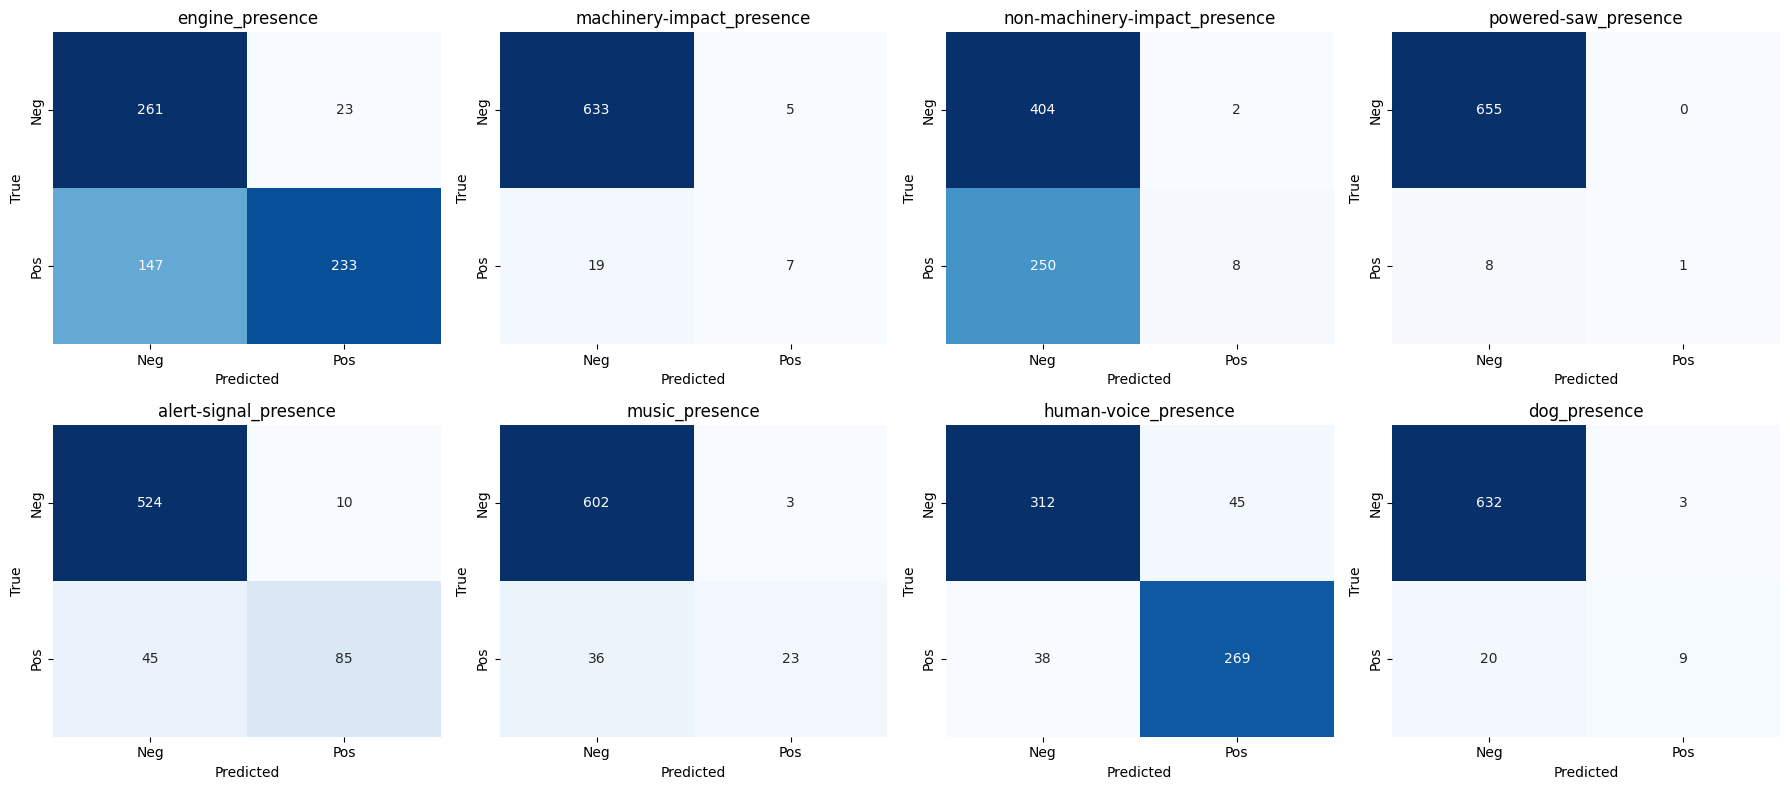

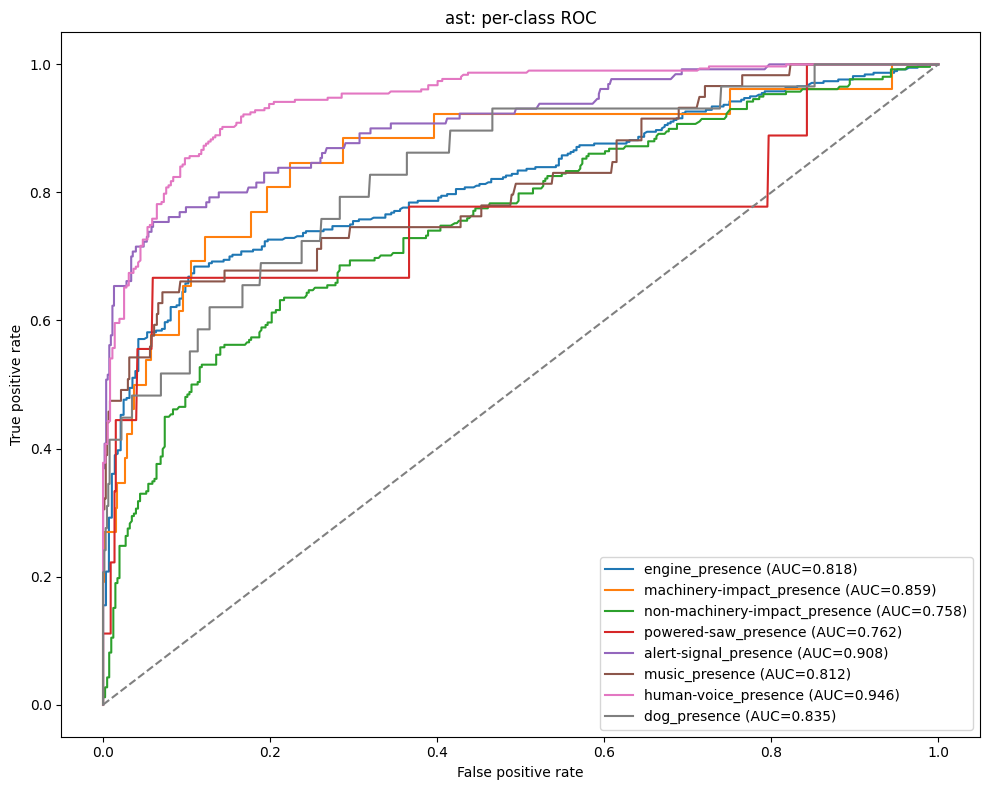

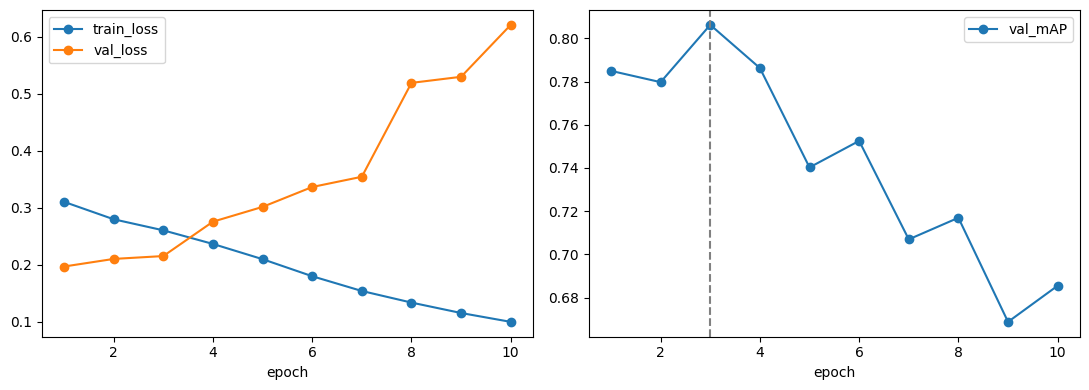

Saved plot images: confusion_matrices.png, roc_curves.png, selection_curves.png
All AST artifacts: /content/drive/MyDrive/A/thesis/normalized_results/AST/native_inputs_v2


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix, roc_curve, auc

# Each class is treated as its own binary decision for this confusion matrix.
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, label, cm in zip(axes.flat, labels, multilabel_confusion_matrix(y_test, predictions)):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    ax.set(title=label, xlabel='Predicted', ylabel='True')
fig.tight_layout()
fig.savefig(AST_OUTPUT_DIR / 'confusion_matrices.png', dpi=150)
plt.show()

# ROC curves use continuous scores and therefore do not depend on THRESHOLD.
fig, ax = plt.subplots(figsize=(10, 8))
for i, label in enumerate(labels):
    if y_test.iloc[:, i].nunique() != 2:
        print(f'Skipping undefined ROC for {label}: only one target class')
        continue
    fpr, tpr, _ = roc_curve(y_test.iloc[:, i], probabilities_positive_class[:, i])
    ax.plot(fpr, tpr, label=f'{label} (AUC={auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title=f'{MODEL_NAME}: per-class ROC')
ax.legend()
fig.tight_layout()
fig.savefig(AST_OUTPUT_DIR / 'roc_curves.png', dpi=150)
plt.show()

# Show the model-selection trajectory: loss and validation mAP; the vertical line marks best epoch.
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hist.plot(x='epoch', y=['train_loss', 'val_loss'], marker='o', ax=axes[0])
hist.plot(x='epoch', y='val_mAP', marker='o', ax=axes[1])
axes[1].axvline(best_epoch, color='gray', linestyle='--')
fig.tight_layout()
fig.savefig(AST_OUTPUT_DIR / 'selection_curves.png', dpi=150)
plt.show()

# The diagnostic PNGs are saved alongside this model's checkpoints and CSV/JSON artifacts.
AST_PLOT_FILES = [
    AST_OUTPUT_DIR / 'confusion_matrices.png',
    AST_OUTPUT_DIR / 'roc_curves.png',
    AST_OUTPUT_DIR / 'selection_curves.png',
]
missing_plots = [p.name for p in AST_PLOT_FILES if not p.exists()]
if missing_plots:
    raise RuntimeError(f"Plot files were not saved: {missing_plots}")
print('Saved plot images:', ', '.join(p.name for p in AST_PLOT_FILES))
print('All AST artifacts:', AST_OUTPUT_DIR)
